# IMPORT THƯ VIỆN

In [100]:
import pandas as pd
import numpy as np
import warnings

# Ignoring warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pickle

In [99]:
import pandas as pd
url = 'https://drive.google.com/file/d/15QjWRzrO9sns02e4kuq_ioihXbVcatkX/view?usp=drive_link'
url = 'https://drive.google.com/uc?id=' + url.split('/')[-2]
df = pd.read_csv(url)
df

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91108,4,1/60,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1/50,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1/00,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2/70,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1/00,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,29,3,40,92697,1,1/90,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0/40,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0/30,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0/50,2,0,0,0,0,1,0


In [101]:
df.shape

(5000, 14)

In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ID                  5000 non-null   int64 
 1   Age                 5000 non-null   int64 
 2   Experience          5000 non-null   int64 
 3   Income              5000 non-null   int64 
 4   ZIP Code            5000 non-null   int64 
 5   Family              5000 non-null   int64 
 6   CCAvg               5000 non-null   object
 7   Education           5000 non-null   int64 
 8   Mortgage            5000 non-null   int64 
 9   Personal Loan       5000 non-null   int64 
 10  Securities Account  5000 non-null   int64 
 11  CD Account          5000 non-null   int64 
 12  Online              5000 non-null   int64 
 13  CreditCard          5000 non-null   int64 
dtypes: int64(13), object(1)
memory usage: 547.0+ KB


# TIỀN XỬ LÝ DỮ LIỆU 

In [103]:
# chuyển đổi kiểu dữ liệu
df['CCAvg'] = df['CCAvg'].str.replace('/', '.').astype('float64')


In [104]:
# Xóa các cột ID và ZIP Code
df = df.drop(columns=["ID", "ZIP Code"])

In [105]:
df.columns

Index(['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education',
       'Mortgage', 'Personal Loan', 'Securities Account', 'CD Account',
       'Online', 'CreditCard'],
      dtype='object')

In [106]:
# Kiểm tra null
df.isnull().sum()

Age                   0
Experience            0
Income                0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

In [107]:
numeric_cols = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Education",
    "Mortgage"
]

df[numeric_cols].describe()

,Age,Experience,Income,CCAvg,Education,Mortgage
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,45.338400,20.104600,73.774200,1.937938,1.881000,56.498800
std,11.463166,11.467954,46.033729,1.747659,0.839869,101.713802
min,23.000000,-3.000000,8.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,2.500000,3.000000,101.000000
max,67.000000,43.000000,224.000000,10.000000,3.000000,635.000000


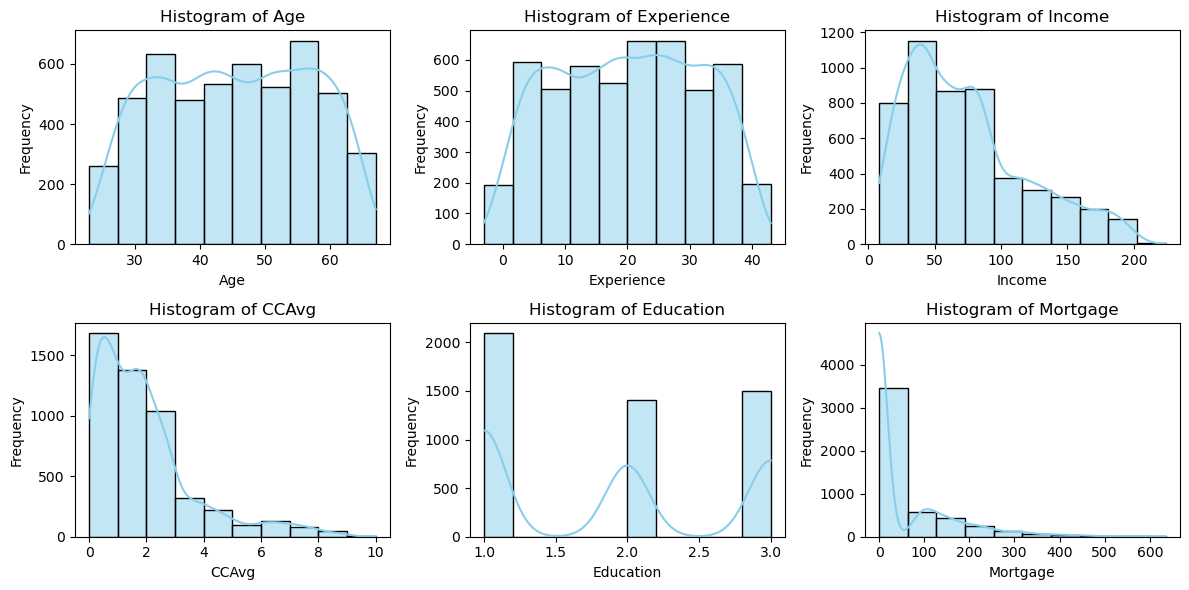

In [108]:
# kiểm tra phân phối dữ liệu
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Education",
    "Mortgage"
]

plt.figure(figsize=(12, 6))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], bins=10, kde=True, color="skyblue")
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

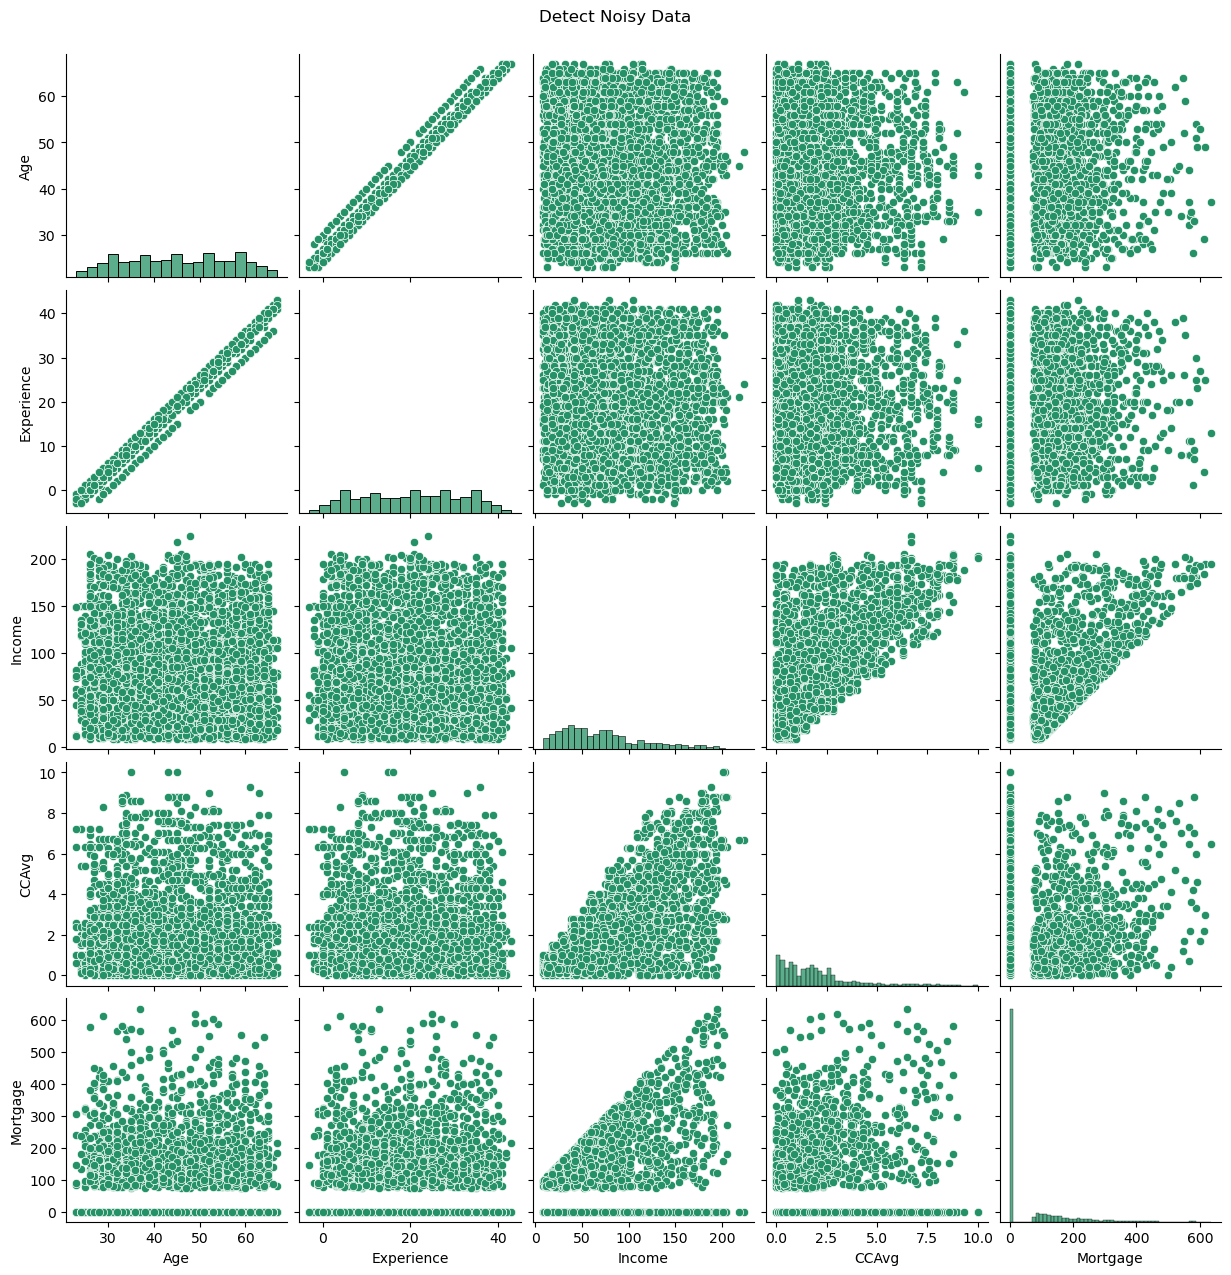

In [56]:
# Check noisy data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

sns.set_palette('summer')

cols = ['Age', 'Experience', 'Income', 'CCAvg', 'Mortgage']

dnp = sns.pairplot(df[cols])

dnp.fig.suptitle('Detect Noisy Data', y=1.02)

plt.show()

In [109]:
# Đếm Experience âm
print("Experience âm:", (df["Experience"] < 0).sum())

Experience âm: 52


In [110]:
# Kiểm tra các giá trị bằng 0
print("Mortgage bằng 0:", (df["Mortgage"] == 0).sum())

Mortgage bằng 0: 3462


In [111]:
# Kiểm tra các giá trị âm
for col in cols:
    print(f"{col} âm:", (df[col] < 0).sum())

Age âm: 0
Experience âm: 52
Income âm: 0
CCAvg âm: 0
Mortgage âm: 0


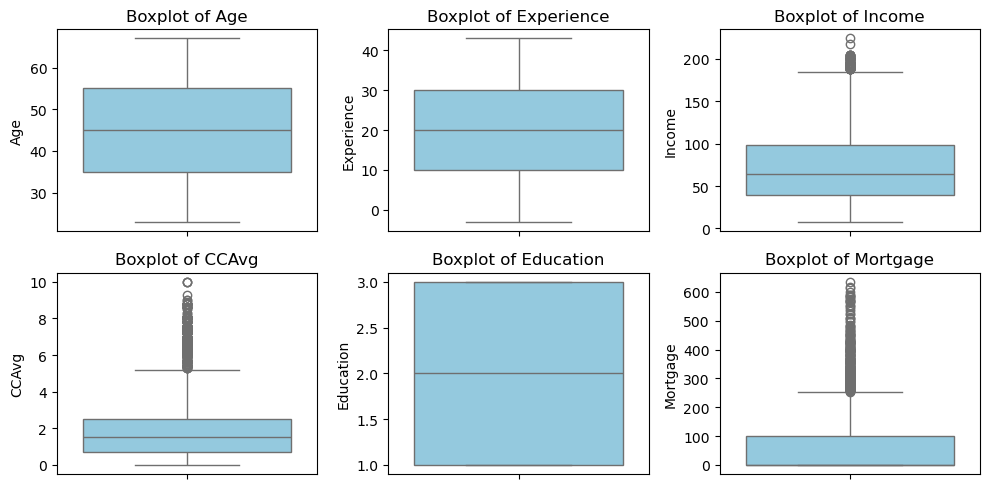

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Education",
    "Mortgage"
]

plt.figure(figsize=(10, 5))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [113]:
# xử lý outlier
df= df.copy()

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower,
        upper=upper
    )

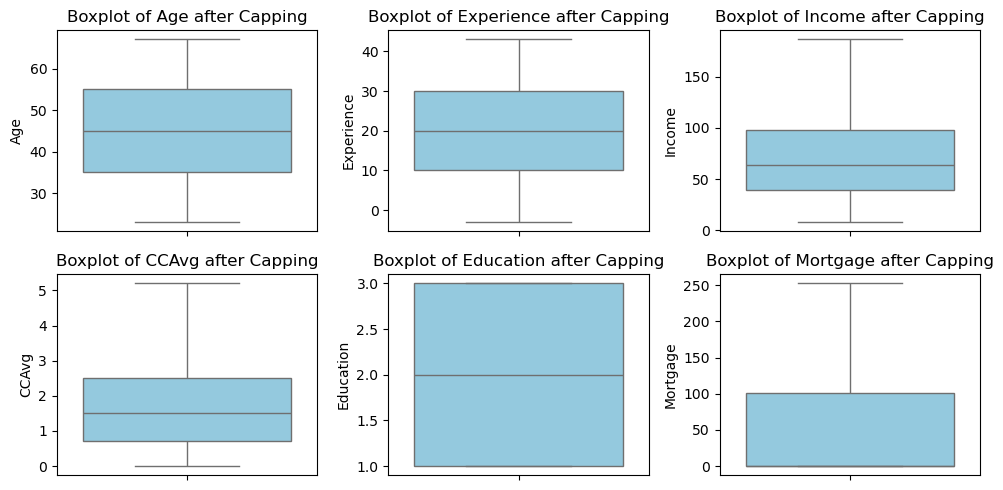

In [114]:
# Kiểm tra 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(f"Boxplot of {col} after Capping")

plt.tight_layout()
plt.show()

In [115]:
# convert annual income to monthly with divide by 12
df['Income'] = round(df['Income']/12, 2)
df

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,4.08,4,1.6,1,0.0,0,1,0,0,0
1,45,19,2.83,3,1.5,1,0.0,0,1,0,0,0
2,39,15,0.92,1,1.0,1,0.0,0,0,0,0,0
3,35,9,8.33,1,2.7,2,0.0,0,0,0,0,0
4,35,8,3.75,4,1.0,2,0.0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,29,3,3.33,1,1.9,3,0.0,0,0,0,1,0
4996,30,4,1.25,4,0.4,1,85.0,0,0,0,1,0
4997,63,39,2.00,2,0.3,3,0.0,0,0,0,0,0
4998,65,40,4.08,3,0.5,2,0.0,0,0,0,1,0


In [116]:
numeric_cols = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Education",
    "Mortgage"
]

df[numeric_cols].describe()

,Age,Experience,Income,CCAvg,Education,Mortgage
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,45.338400,20.104600,6.134804,1.831338,1.881000,50.494700
std,11.463166,11.467954,3.802163,1.452215,0.839869,83.005401
min,23.000000,-3.000000,0.670000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,3.250000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,5.330000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,8.170000,2.500000,3.000000,101.000000
max,67.000000,43.000000,15.540000,5.200000,3.000000,252.500000


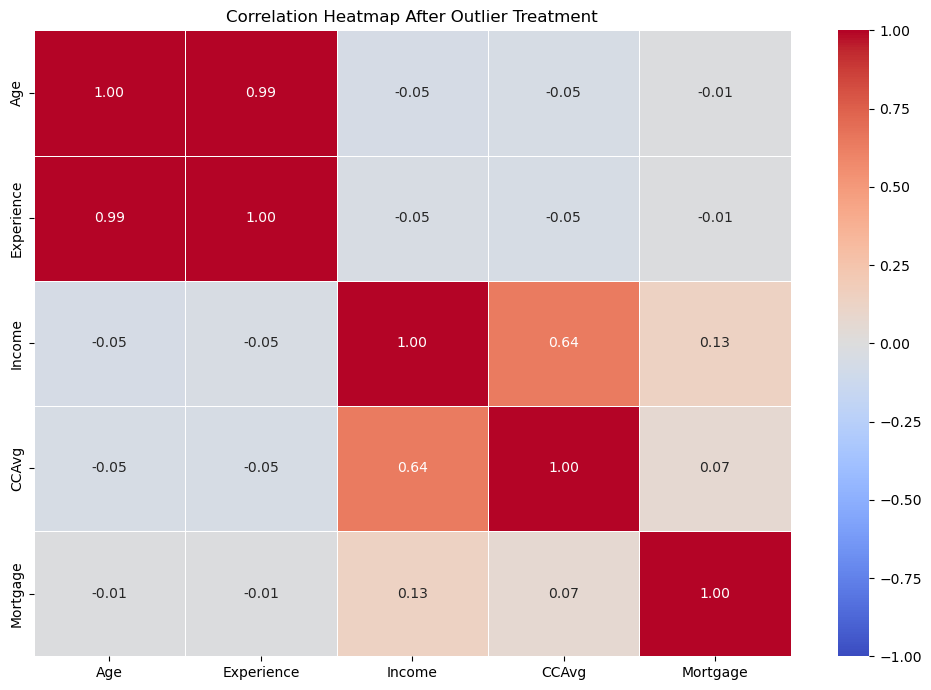

In [117]:
# vẽ biểu đồ heatmap
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "Age",
    "Experience",
    "Income",
    "CCAvg",
    "Mortgage"
]

# Tính ma trận tương quan sau khi làm sạch outlier
corr_matrix = df[numeric_cols].corr()

# Vẽ Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap After Outlier Treatment")
plt.tight_layout()
plt.show()

In [118]:
# Tương quan của các biến với Personal Loan
corr = df.corr(numeric_only=True)

print(
    corr["Personal Loan"]
    .sort_values(ascending=False)
)

Personal Loan         1.000000
Income                0.504562
CCAvg                 0.383306
CD Account            0.316355
Education             0.136722
Mortgage              0.092989
Family                0.061367
Securities Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
Name: Personal Loan, dtype: float64


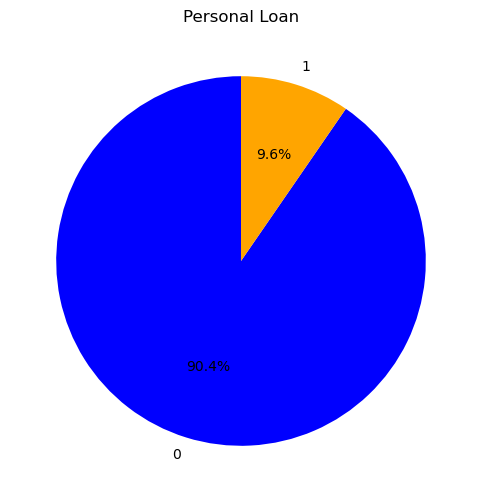

In [119]:
# Đếm số lượng khách hàng theo trạng thái rời bỏ
churn_counts = df["Personal Loan"].value_counts()

# Vẽ biểu đồ tròn
plt.figure(figsize=(6, 6))
plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["blue", "orange"]
)

plt.title("Personal Loan")
plt.show()

# XỬ LÝ MẤT CĂN BẰNG DỮ LIỆU BẰNG SMOKE

In [120]:
X = df.drop(columns=["Personal Loan"])
y = df["Personal Loan"]

In [121]:
# Chia tập train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [122]:
print(y_train.shape)

(4000,)


In [123]:
print(y_train.value_counts())

Personal Loan
0    3625
1     375
Name: count, dtype: int64


In [124]:
# Khởi tạo SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [125]:
print(y_train_smote.value_counts())

Personal Loan
0    3625
1    3625
Name: count, dtype: int64


# SCALING

In [126]:
from sklearn.preprocessing import StandardScaler

# Khởi tạo StandardScaler
scaler = StandardScaler()

# Chuẩn hóa dữ liệu cho X_balanced (hoặc bất kỳ ma trận nào bạn muốn chuẩn hóa)
X_balanced_scaled = scaler.fit_transform(X)
X = X_balanced_scaled
X

array([[-1.77441684, -1.66607847, -0.54048433, ..., -0.25354028,
        -1.21661774, -0.64531434],
       [-0.02952359, -0.09633022, -0.86927744, ..., -0.25354028,
        -1.21661774, -0.64531434],
       [-0.55299157, -0.44516316, -1.37167332, ..., -0.25354028,
        -1.21661774, -0.64531434],
       ...,
       [ 1.54088033,  1.64783451, -1.08759607, ..., -0.25354028,
        -1.21661774, -0.64531434],
       [ 1.71536965,  1.73504275, -0.54048433, ..., -0.25354028,
         0.82195086, -0.64531434],
       [-1.51268285, -1.40445376,  0.20653363, ..., -0.25354028,
         0.82195086,  1.54963239]])

# KHỞI TẠO MÔ HÌNH

In [130]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "Logistic Regression": LogisticRegression( max_iter=1000, random_state=42
    )
}

# KHAI BÁO HÀM ĐÁNH GIÁ

In [131]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

In [132]:
def evaluate_model(model, model_name):

    # 1. Huấn luyện mô hình và dự đoán
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # 2. Lấy điểm dự đoán của lớp 1
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # 3. Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["0 = Not Accepted", "1 = Accepted"],
        yticklabels=["0 = Not Accepted", "1 = Accepted"]
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # 4. Classification Report
    print(f"Classification Report - {model_name}")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    # 5. ROC Curve và ROC-AUC
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.title(f"ROC Curve - {model_name}")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 6. Lưu các chỉ số đánh giá vào danh sách results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": auc
    })

MODEL: Gradient Boosting


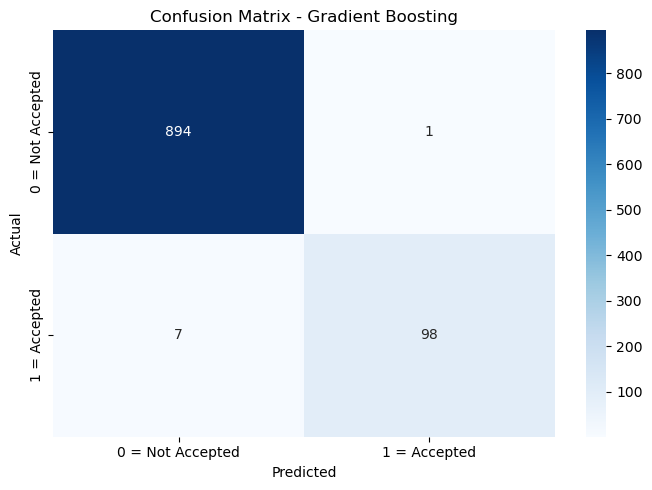

Classification Report - Gradient Boosting
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       895
           1       0.99      0.93      0.96       105

    accuracy                           0.99      1000
   macro avg       0.99      0.97      0.98      1000
weighted avg       0.99      0.99      0.99      1000



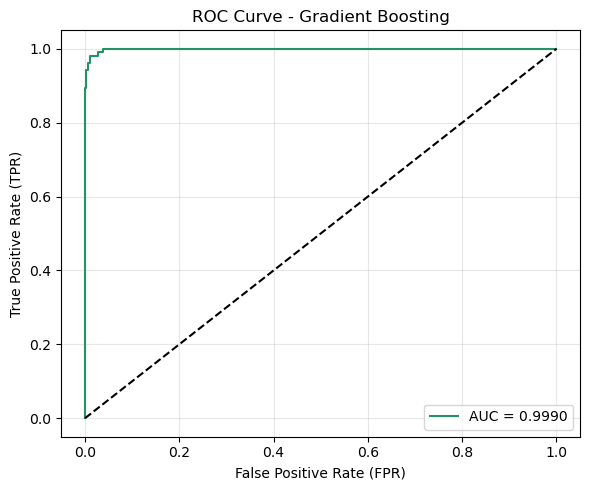

MODEL: Random Forest


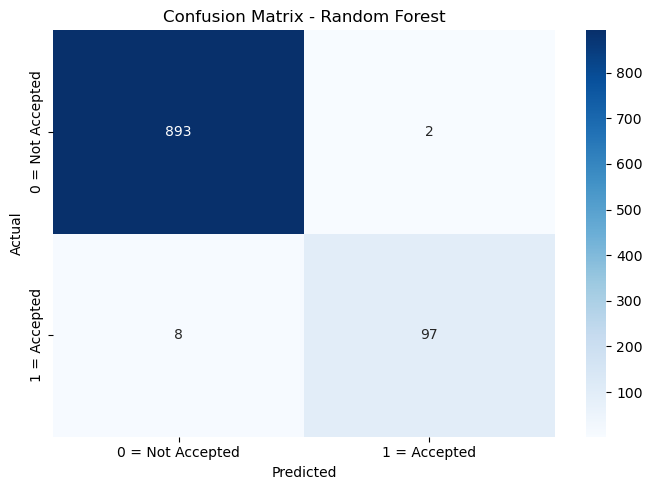

Classification Report - Random Forest
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       895
           1       0.98      0.92      0.95       105

    accuracy                           0.99      1000
   macro avg       0.99      0.96      0.97      1000
weighted avg       0.99      0.99      0.99      1000



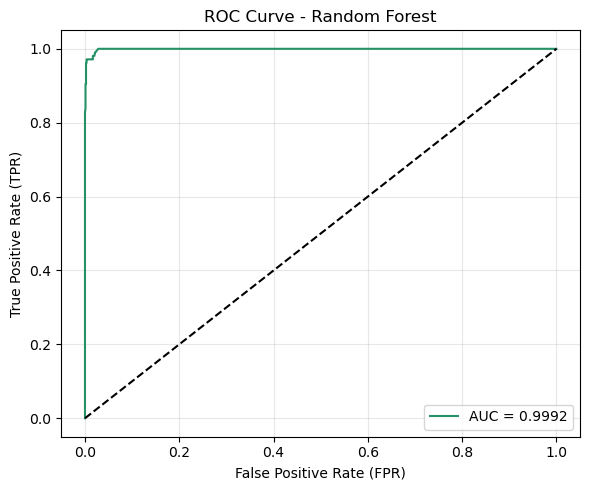

MODEL: XGBoost


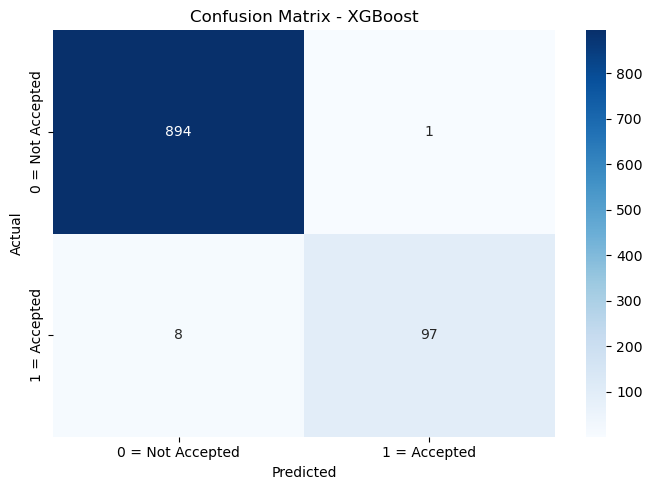

Classification Report - XGBoost
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       895
           1       0.99      0.92      0.96       105

    accuracy                           0.99      1000
   macro avg       0.99      0.96      0.98      1000
weighted avg       0.99      0.99      0.99      1000



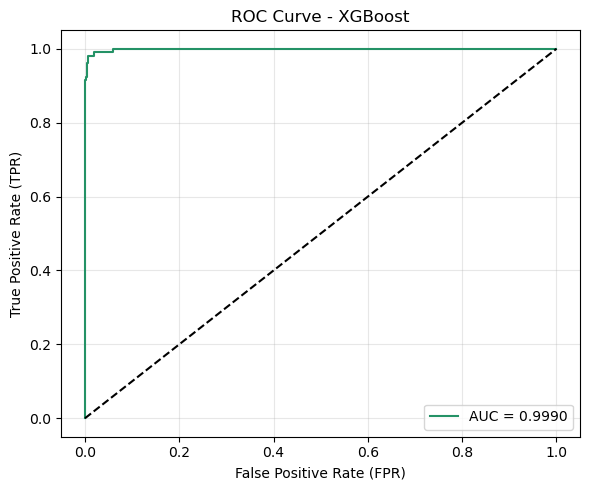

MODEL: Logistic Regression


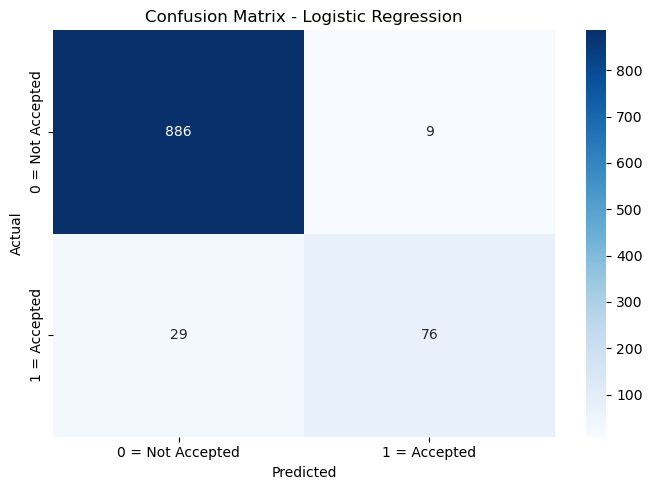

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       895
           1       0.89      0.72      0.80       105

    accuracy                           0.96      1000
   macro avg       0.93      0.86      0.89      1000
weighted avg       0.96      0.96      0.96      1000



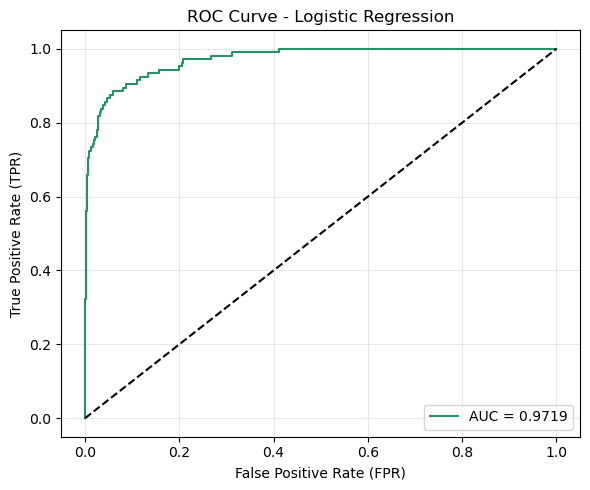

In [136]:
# Xóa kết quả cũ để tránh lưu trùng khi chạy lại
results = []

for model_name, model in models.items():

    print("=" * 40)
    print(f"MODEL: {model_name}")
    print("=" * 40)

    evaluate_model(model, model_name)

In [138]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.992,0.9899,0.9333,0.9608,0.9990
1,XGBoost,0.991,0.9898,0.9238,0.9557,0.9990
2,Random Forest,0.990,0.9798,0.9238,0.9510,0.9992
3,Logistic Regression,0.962,0.8941,0.7238,0.8000,0.9719


In [139]:
# Lấy mô hình Gradient Boosting đã được huấn luyện
gb_model = models["Gradient Boosting"]

# Lấy Feature Importance
gb_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_model.feature_importances_
})

gb_importance_df = gb_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

gb_importance_df.round(4)

,Feature,Importance
0,Education,0.3797
1,Income,0.3571
2,Family,0.1704
3,CCAvg,0.0645
4,CD Account,0.0135
5,Age,0.0086
6,Experience,0.0024
7,Mortgage,0.0015
8,Online,0.0013
9,CreditCard,0.0010


<Figure size 1000x500 with 0 Axes>

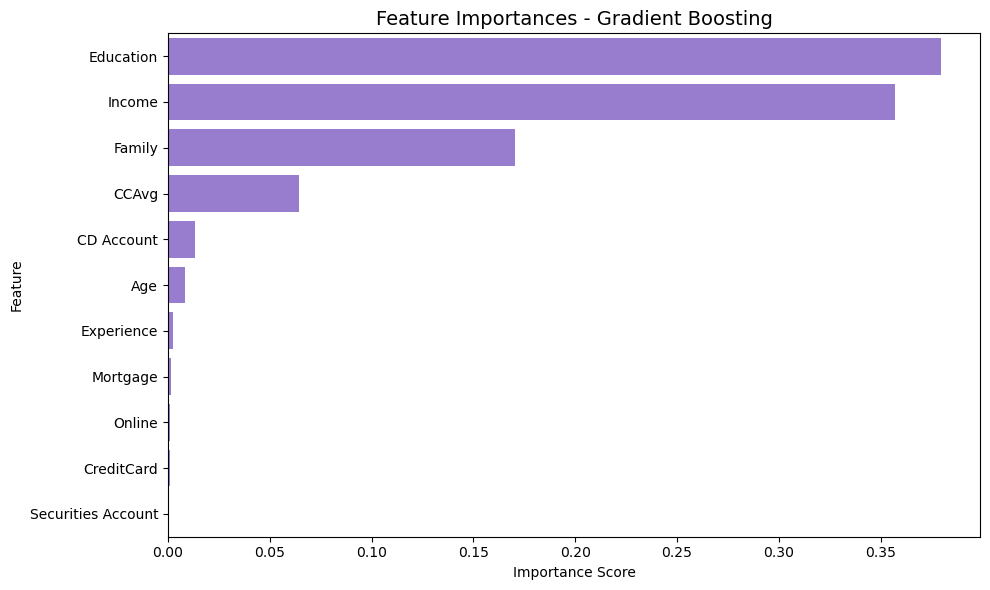

In [140]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=gb_importance_df,
    x="Importance",
    y="Feature",
    color="mediumpurple"
)

plt.title(
    "Feature Importances - Gradient Boosting",
    fontsize=14
)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()